# Agrupamento (clustering) das receitas do governo dos EUA

**Disciplina:** IA / Machine Learning - Aprendizado não supervisionado
**Mini projeto em pares** - Integrantes: _Emili Vieira Tabuti_ e _(nome do colega)_

## 1. Objetivo

Neste trabalho vamos usar **aprendizado não supervisionado** para descobrir grupos de contas de receita do orçamento federal americano (*budget*) que se comportam de forma parecida ao longo do tempo.

- **Dataset:** *Public Budget Database, Budget of the United States Government, Fiscal Year 2016* - tabela de **Receipts** (receitas), `BUDGET-2016-DB-3`
- **Fonte:** https://www.govinfo.gov/app/details/BUDGET-2016-DB/BUDGET-2016-DB-3 (U.S. Government Publishing Office)
- **Valores:** em milhares de dólares, de 1962 a 2020 (de 2016 em diante são **projeções** do orçamento)
- **Modelos:** K-Means (principal), Affinity Propagation, Agrupamento Hierárquico (Ward) e DBSCAN, conforme a [documentação do scikit-learn](https://scikit-learn.org/stable/modules/clustering.html)

Cada linha do dataset é uma **conta de receita** (ex.: imposto de renda, taxa de alfândega, multas...) e as colunas de 1962 até 2020 trazem quanto ela arrecadou em cada ano.

> Observação: o dataset original citado na atividade era do Kaggle, mas o escolhido foi esse do `govinfo.gov` (também público), então ele está salvo em `data/`.

## 2. Importando as bibliotecas

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AffinityPropagation, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 3. Carregando os dados

In [2]:
df = pd.read_csv("data/BUDGET-2016-DB-3.csv", thousands=",")

# nomes de colunas mais curtos
df = df.rename(columns={
    "Source Category Code": "cod_categoria",
    "Source category name": "categoria",
    "Source subcategory": "cod_subcategoria",
    "Source subcategory name": "subcategoria",
    "Agency code": "cod_agencia",
    "Agency name": "agencia",
    "Bureau code": "cod_bureau",
    "Bureau name": "bureau",
    "Account code": "cod_conta",
    "Account name": "conta",
    "Treasury Agency code": "cod_tesouro",
    "On- or off-budget": "orcamento",
})

print("Linhas x colunas:", df.shape)
df.head()

Linhas x colunas: (237, 72)


,cod_categoria,categoria,cod_subcategoria,subcategoria,cod_agencia,agencia,cod_bureau,bureau,cod_conta,conta,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,931,Individual Income Taxes,0,Individual Income Taxes,9,Department of Health and Human Services,0,Department of Health and Human Services,800415,"Supplemental Catastrophic Premium, Refunds, FSMI",...,0,0,0,0,0,0,0,0,0,0
1,931,Individual Income Taxes,0,Individual Income Taxes,9,Department of Health and Human Services,0,Department of Health and Human Services,818210,FHICCR supplemental catastrophic premium,...,0,0,0,0,0,0,0,0,0,0
2,931,Individual Income Taxes,0,Individual Income Taxes,15,Department of the Treasury,0,Department of the Treasury,551010,Private Collection Agent Program,...,0,0,0,0,0,0,0,0,0,0
3,931,Individual Income Taxes,0,Individual Income Taxes,901,Governmental Receipts,0,Governmental Receipts,11050,Individual Income Taxes,...,1091433000,1132169000,1316370000,1394538000,1478026000,1645578000,1770297000,1886834000,1999750000,2118356000
4,931,Individual Income Taxes,0,Individual Income Taxes,901,Governmental Receipts,0,Governmental Receipts,508110,Presidential Election Campaign Fund,...,40000,37000,35000,30000,50000,50000,50000,50000,50000,50000


## 4. Análise exploratória (EDA)

### 4.1 Estrutura e qualidade dos dados

In [3]:
df.info(max_cols=14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Columns: 72 entries, cod_categoria to 2020
dtypes: int64(66), object(6)
memory usage: 133.4+ KB


In [4]:
anos_todos = [c for c in df.columns if c.isdigit()]
print("Colunas de ano:", anos_todos[0], "->", anos_todos[-1], f"({len(anos_todos)} anos) + coluna TQ (trimestre de transição de 1976)")
print("Valores nulos:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
print("Contas com nome repetido:", int(df["conta"].duplicated().sum()))
df.iloc[:, :12].nunique().to_frame("valores distintos")

Colunas de ano: 1962 -> 2020 (59 anos) + coluna TQ (trimestre de transição de 1976)
Valores nulos: 0
Linhas duplicadas: 0
Contas com nome repetido: 5


,valores distintos
cod_categoria,8
categoria,8
cod_subcategoria,4
subcategoria,12
cod_agencia,40
agencia,40
cod_bureau,6
bureau,42
cod_conta,231
conta,232


Não há valores nulos. Quando uma conta não existia em determinado ano, o valor é simplesmente **0**. As colunas de identificação (categoria, agência, etc.) são textuais e os anos são numéricos.

### 4.2 Variáveis categóricas

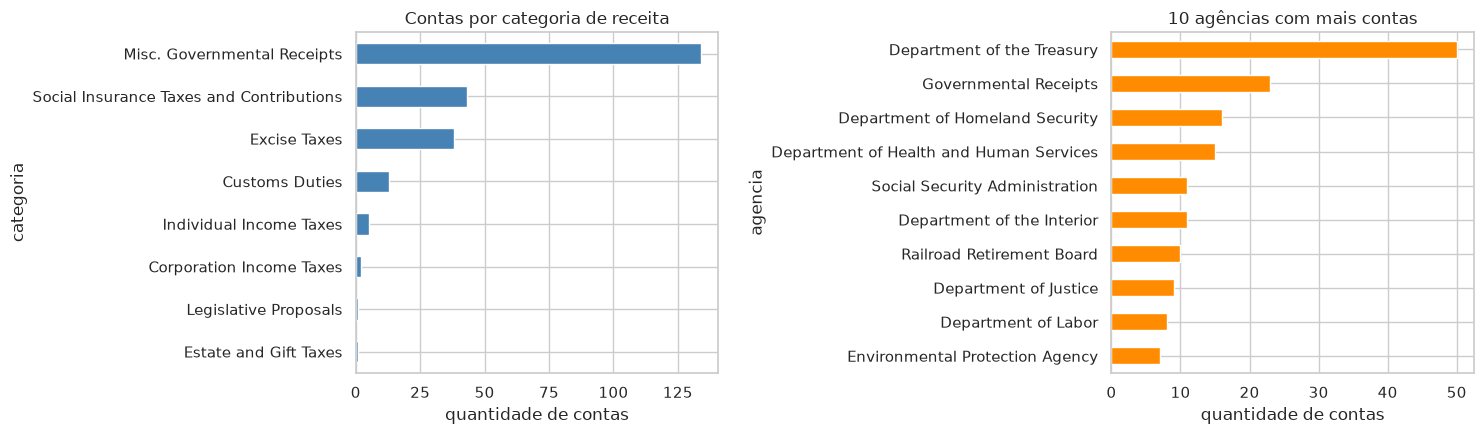

orcamento
On-budget     227
Off-budget     10


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

df["categoria"].value_counts().sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Contas por categoria de receita")
axes[0].set_xlabel("quantidade de contas")

df["agencia"].value_counts().head(10).sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("10 agências com mais contas")
axes[1].set_xlabel("quantidade de contas")

plt.tight_layout()
plt.show()

print(df["orcamento"].value_counts().to_string())

### 4.3 Receita ao longo do tempo

Soma da arrecadação por categoria (em bilhões de dólares). A linha tracejada separa o que foi arrecadado (até 2015) do que é **projeção** (2016-2020).

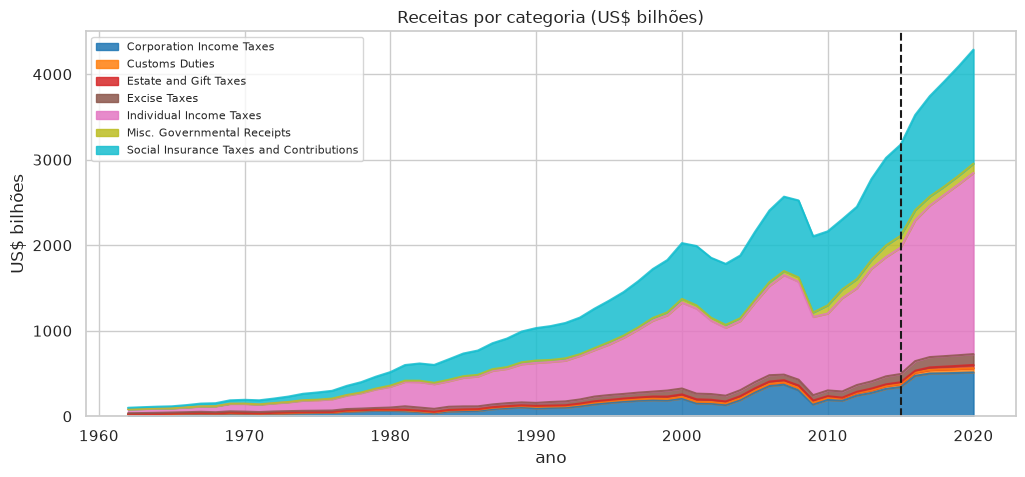

In [6]:
anos = [str(a) for a in range(1962, 2021)]
por_cat = df.groupby("categoria")[anos].sum().T / 1e6   # milhares -> bilhões
por_cat.index = por_cat.index.astype(int)

ax = por_cat.drop(columns="Legislative Proposals").plot.area(figsize=(12, 5), cmap="tab10", alpha=0.85)
ax.axvline(2015, color="k", ls="--")
ax.set_title("Receitas por categoria (US$ bilhões)")
ax.set_xlabel("ano"); ax.set_ylabel("US$ bilhões")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### 4.4 Distribuição dos valores

A arrecadação varia muito entre contas (de alguns milhares até mais de 1 trilhão de dólares), então vale olhar em escala logarítmica. Como existem valores **negativos** (reembolsos) e **zeros**, vamos usar a transformação *sinal x log10(1 + |x|)*.

count    2.370000e+02
mean     1.340115e+07
std      1.072227e+08
min     -3.398000e+06
25%      0.000000e+00
50%      4.000000e+03
75%      2.040000e+05
max      1.478026e+09


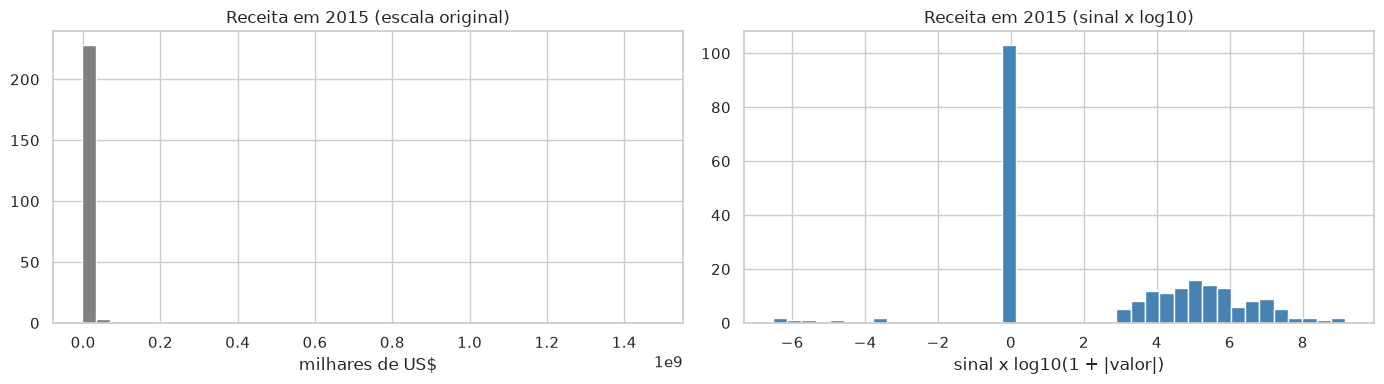

Zeros na série 1962-2015: 67.9% | valores negativos: 273


In [7]:
def slog(x):
    # log com sinal: aguenta zero e valores negativos
    return np.sign(x) * np.log10(1 + np.abs(x))

v2015 = df["2015"]
print(v2015.describe().round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(v2015, bins=40, color="gray")
axes[0].set_title("Receita em 2015 (escala original)")
axes[0].set_xlabel("milhares de US$")

axes[1].hist(slog(v2015), bins=40, color="steelblue")
axes[1].set_title("Receita em 2015 (sinal x log10)")
axes[1].set_xlabel("sinal x log10(1 + |valor|)")
plt.tight_layout()
plt.show()

hist = df[[str(a) for a in range(1962, 2016)]]
print(f"Zeros na série 1962-2015: {(hist == 0).mean().mean():.1%} | valores negativos: {(hist < 0).sum().sum()}")

Poucas contas concentram quase toda a arrecadação (cauda longa), e mais da metade dos valores do histórico é zero, porque muitas contas só existiram por um período.

In [8]:
top = df.assign(total_1962_2015=hist.sum(axis=1)).nlargest(8, "total_1962_2015")
(top[["categoria", "conta", "total_1962_2015"]]
    .assign(total_1962_2015=lambda d: (d.total_1962_2015 / 1e6).round(0))
    .rename(columns={"total_1962_2015": "total (US$ bi)"})
    .reset_index(drop=True))

,categoria,conta,total (US$ bi)
0,Individual Income Taxes,Individual Income Taxes,28227.0
1,Social Insurance Taxes and Contributions,"FOASI, Transfers from General Fund (FICA Taxes)",11735.0
2,Corporation Income Taxes,Corporation Income and Excess Profits Taxes,6577.0
3,Social Insurance Taxes and Contributions,"FHI Trust Fund, Transfers from General Fund (F...",3841.0
4,Social Insurance Taxes and Contributions,"FDI, Transfers from General Fund (FICA Taxes)",1844.0
5,Social Insurance Taxes and Contributions,FOASI Trust Fund Receipts,1132.0
6,Misc. Governmental Receipts,"Deposit of Earnings, Federal Reserve System",1100.0
7,Excise Taxes,"Transportation Trust Fund, Deposits (Highway A...",911.0


### 4.5 Mapa de calor das contas

Cada linha é uma conta e cada coluna um ano (cor = sinal x log10 do valor). Dá para ver visualmente que existem contas "antigas e grandes", contas que **nasceram** ou **morreram** no meio do período e contas bem pequenas - o que sugere que há grupos naturais nos dados.

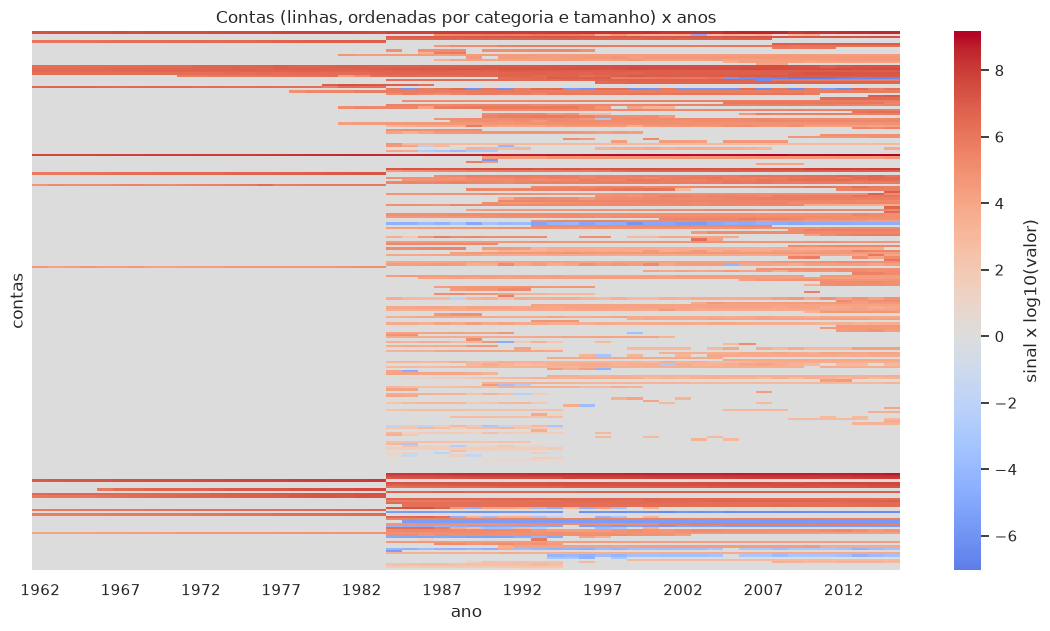

In [9]:
ordem = df.assign(t=hist.abs().sum(axis=1)).sort_values(["categoria", "t"], ascending=[True, False]).index
plt.figure(figsize=(14, 7))
sns.heatmap(slog(hist.loc[ordem]).values, cmap="coolwarm", center=0,
            xticklabels=5, yticklabels=False, cbar_kws={"label": "sinal x log10(valor)"})
plt.xticks(np.arange(0, 54, 5) + 0.5, range(1962, 2016, 5), rotation=0)
plt.title("Contas (linhas, ordenadas por categoria e tamanho) x anos")
plt.xlabel("ano"); plt.ylabel("contas")
plt.show()

## 5. Preparação dos dados para o clustering

Como o K-Means usa **distância**, não dá para usar as 54 colunas de ano diretamente (seriam muito correlacionadas e dominadas pelas contas gigantes). Então vamos criar **uma linha de características por conta** que descrevem o comportamento dela de 1962 a 2015 (só dados realizados, sem as projeções):

| Característica | O que representa |
|---|---|
| `log_total` | tamanho total arrecadado (log) |
| `log_recente` | média de 2011-2015 (log com sinal) |
| `anos_ativos` | quantos anos teve valor diferente de zero |
| `ano_inicio` / `ano_fim` | primeiro / último ano ativo |
| `pct_neg` | proporção dos anos ativos com valor negativo (reembolsos) |
| `cv` | coeficiente de variação (instabilidade), limitado a 5 |
| `crescimento` | log da média 2006-2015 menos log da média 1996-2005 |
| `off_budget` | 1 se é receita fora do orçamento (ex.: Seguro Social) |

In [10]:
anos_hist = [str(a) for a in range(1962, 2016)]
V = df[anos_hist].to_numpy(dtype=float)
ativo = V != 0

sem_atividade = ~ativo.any(axis=1)
print("Contas sem nenhum valor em 1962-2015 (só projeção):", int(sem_atividade.sum()))
print(df.loc[sem_atividade, ["categoria", "conta"]].to_string())

Contas sem nenhum valor em 1962-2015 (só projeção): 7
                       categoria                                                                                           conta
71                  Excise Taxes                                                Excise Tax on High Cost Employer-Sponsored Plans
129  Misc. Governmental Receipts                                                                       Hardrock Reclamation Fees
157  Misc. Governmental Receipts                                      Transitional Reinsurance Contributions to the General Fund
167  Misc. Governmental Receipts  Penalties on Employers Who Do not Offer Health Coverage or Delay Eligibility for New Employees
172  Misc. Governmental Receipts                                                      Premiums, Terrorism Risk Insurance Program
210  Misc. Governmental Receipts                                                         Users Fees, Inland Waterways Trust Fund
236        Legislative Proposals           

In [11]:
# remove contas sem histórico: não há comportamento passado para agrupar
base = df.loc[~sem_atividade].reset_index(drop=True)
V = base[anos_hist].to_numpy(dtype=float)
ativo = V != 0
n_ativo = ativo.sum(axis=1)
anos_arr = np.arange(1962, 2016)

media_ativa = np.array([v[a].mean() for v, a in zip(V, ativo)])
std_ativa = np.array([v[a].std() for v, a in zip(V, ativo)])

X_df = pd.DataFrame({
    "log_total": np.log10(1 + np.abs(V).sum(axis=1)),
    "log_recente": slog(V[:, -5:].mean(axis=1)),
    "anos_ativos": n_ativo,
    "ano_inicio": [anos_arr[a][0] for a in ativo],
    "ano_fim": [anos_arr[a][-1] for a in ativo],
    "pct_neg": (V < 0).sum(axis=1) / n_ativo,
    "cv": np.clip(std_ativa / np.maximum(np.abs(media_ativa), 1e-9), 0, 5),
    "crescimento": slog(V[:, -10:].mean(axis=1)) - slog(V[:, -20:-10].mean(axis=1)),
    "off_budget": (base["orcamento"] == "Off-budget").astype(int),
})
print("Shape:", X_df.shape, "| nulos:", int(X_df.isna().sum().sum()))
X_df.describe().T.round(2)

Shape: (230, 9) | nulos: 0


,count,mean,std,min,25%,50%,75%,max
log_total,230.0,5.98,1.62,1.43,4.95,5.97,7.00,10.45
log_recente,230.0,2.82,3.10,-6.68,0.00,3.59,5.35,9.11
anos_ativos,230.0,17.83,13.29,1.00,5.00,16.00,31.00,54.00
ano_inicio,230.0,1989.37,12.70,1962.00,1984.00,1985.00,1994.75,2015.00
ano_fim,230.0,2006.88,11.07,1983.00,1997.00,2015.00,2015.00,2015.00
pct_neg,230.0,0.08,0.23,0.00,0.00,0.00,0.00,1.00
cv,230.0,0.78,1.07,0.00,0.23,0.46,0.80,5.00
crescimento,230.0,0.59,2.46,-13.06,0.00,0.03,0.71,10.37
off_budget,230.0,0.04,0.20,0.00,0.00,0.00,0.00,1.00


### 5.1 Distribuição e correlação das características

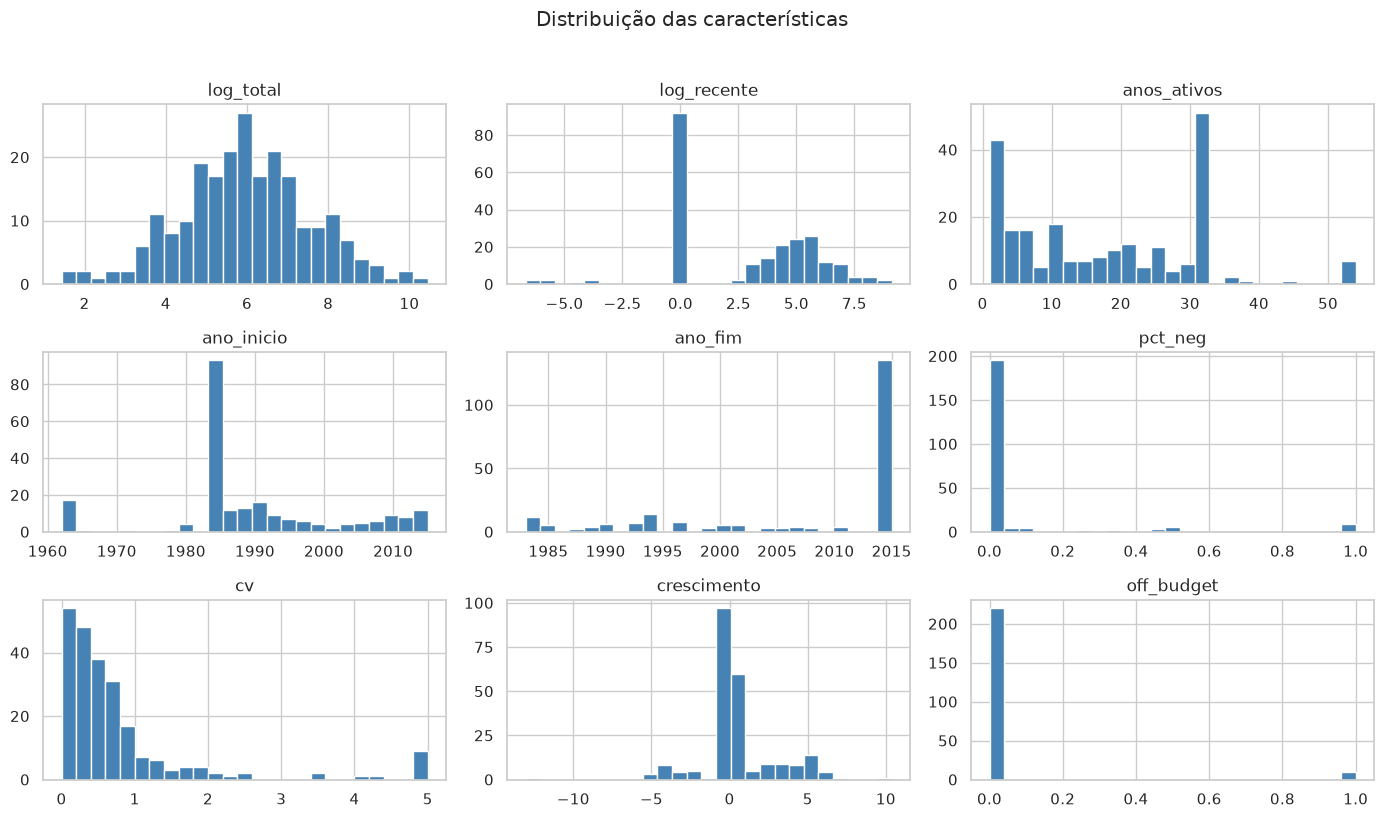

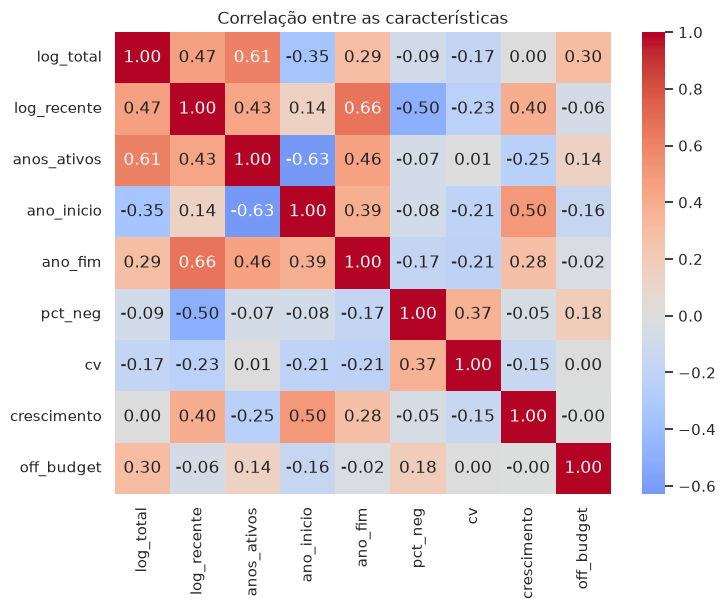

In [12]:
X_df.hist(figsize=(14, 8), bins=25, color="steelblue")
plt.suptitle("Distribuição das características", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(X_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre as características")
plt.show()

Há correlações esperadas (`log_total` com `anos_ativos` e `log_recente`), mas nenhuma característica é redundante a ponto de ser descartada. As variáveis estão em escalas muito diferentes (anos vs. proporções), então aplicamos **padronização** (`StandardScaler`) antes de clusterizar.

In [13]:
X = StandardScaler().fit_transform(X_df)

pca = PCA(random_state=RANDOM_STATE).fit(X)
var_acum = pca.explained_variance_ratio_.cumsum()
print("Variância explicada acumulada:", np.round(var_acum, 2))

pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X)
print(f"2 componentes explicam {pca2.explained_variance_ratio_.sum():.1%} da variância (usaremos só para visualizar)")

Variância explicada acumulada: [0.3  0.56 0.69 0.8  0.88 0.94 0.98 1.   1.  ]
2 componentes explicam 55.7% da variância (usaremos só para visualizar)


## 6. K-Means

### 6.1 Escolhendo o número de clusters (k)

Testamos k de 2 a 10 e olhamos o **método do cotovelo** (inércia) e o **coeficiente de silhueta** (quanto maior, melhor separados os grupos).

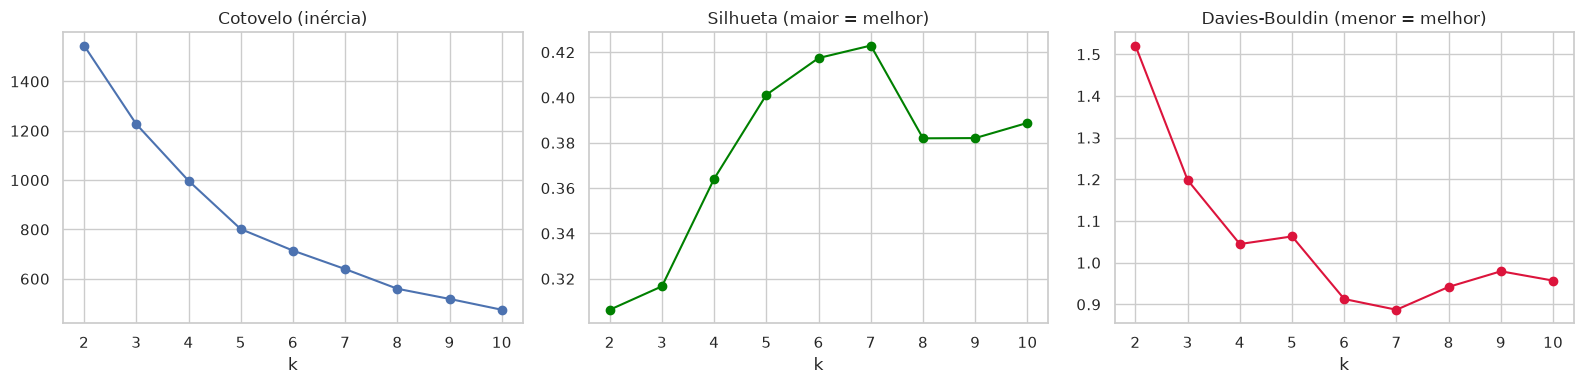

,k,inércia,silhueta,davies_bouldin
0,2,1545.311,0.306,1.521
1,3,1226.680,0.317,1.198
2,4,997.487,0.364,1.045
3,5,801.493,0.401,1.063
4,6,714.276,0.417,0.913
5,7,639.381,0.423,0.887
6,8,559.571,0.382,0.942
7,9,518.329,0.382,0.979
8,10,474.407,0.389,0.957


In [14]:
ks = range(2, 11)
inercia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    dbi.append(davies_bouldin_score(X, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ks, inercia, "o-"); axes[0].set_title("Cotovelo (inércia)")
axes[1].plot(ks, sil, "o-", color="green"); axes[1].set_title("Silhueta (maior = melhor)")
axes[2].plot(ks, dbi, "o-", color="crimson"); axes[2].set_title("Davies-Bouldin (menor = melhor)")
for a in axes: a.set_xlabel("k")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(ks), "inércia": inercia, "silhueta": sil, "davies_bouldin": dbi}).round(3)

### 6.2 Modelo final

In [15]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X)
base["cluster"] = kmeans.labels_
X_df["cluster"] = kmeans.labels_

print(f"k = {K} | silhueta = {silhouette_score(X, kmeans.labels_):.3f}")
print(base["cluster"].value_counts().sort_index().to_string())

k = 5 | silhueta = 0.401
cluster
0    90
1    45
2    10
3    63
4    22


### 6.3 Visualização dos clusters (PCA 2D)

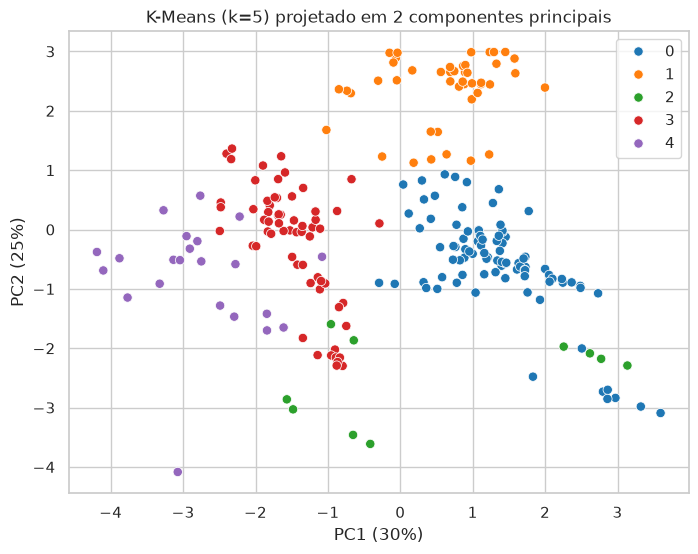

In [16]:
def plot_pca(labels, titulo, ax):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette="tab10", s=45, ax=ax, legend="full")
    ax.set_title(titulo)
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%})")

fig, ax = plt.subplots(figsize=(8, 6))
plot_pca(kmeans.labels_, f"K-Means (k={K}) projetado em 2 componentes principais", ax)
plt.show()

### 6.4 Perfil de cada cluster

In [17]:
perfil = X_df.groupby("cluster").agg(["mean"]).round(2)
perfil.columns = [c[0] for c in perfil.columns]
perfil.insert(0, "n_contas", X_df["cluster"].value_counts().sort_index())
perfil

,n_contas,log_total,log_recente,anos_ativos,ano_inicio,ano_fim,pct_neg,cv,crescimento,off_budget
cluster,,,,,,,,,,
0,90,6.73,5.13,30.41,1984.74,2014.79,0.01,0.73,0.27,0.0
1,45,5.56,4.29,5.47,2009.11,2014.02,0.00,0.20,3.94,0.0
2,10,8.24,1.91,26.40,1979.60,2005.60,0.27,0.81,0.53,1.0
3,63,5.20,0.00,9.71,1984.32,1993.89,0.01,0.57,-1.01,0.0
4,22,4.93,-1.13,11.05,1986.77,1997.68,0.63,2.77,-0.37,0.0


In [18]:
# quanto cada cluster representa da arrecadação total 1962-2015
base["total_hist"] = V.sum(axis=1)
resumo = base.groupby("cluster").agg(n_contas=("conta", "size"), total_bi=("total_hist", lambda s: s.sum() / 1e6))
resumo["% do total"] = (100 * resumo["total_bi"] / resumo["total_bi"].sum()).round(1)
resumo["total_bi"] = resumo["total_bi"].round(0)
resumo

,n_contas,total_bi,% do total
cluster,,,
0,90,45160.0,73.0
1,45,159.0,0.3
2,10,15693.0,25.4
3,63,892.0,1.4
4,22,-11.0,-0.0


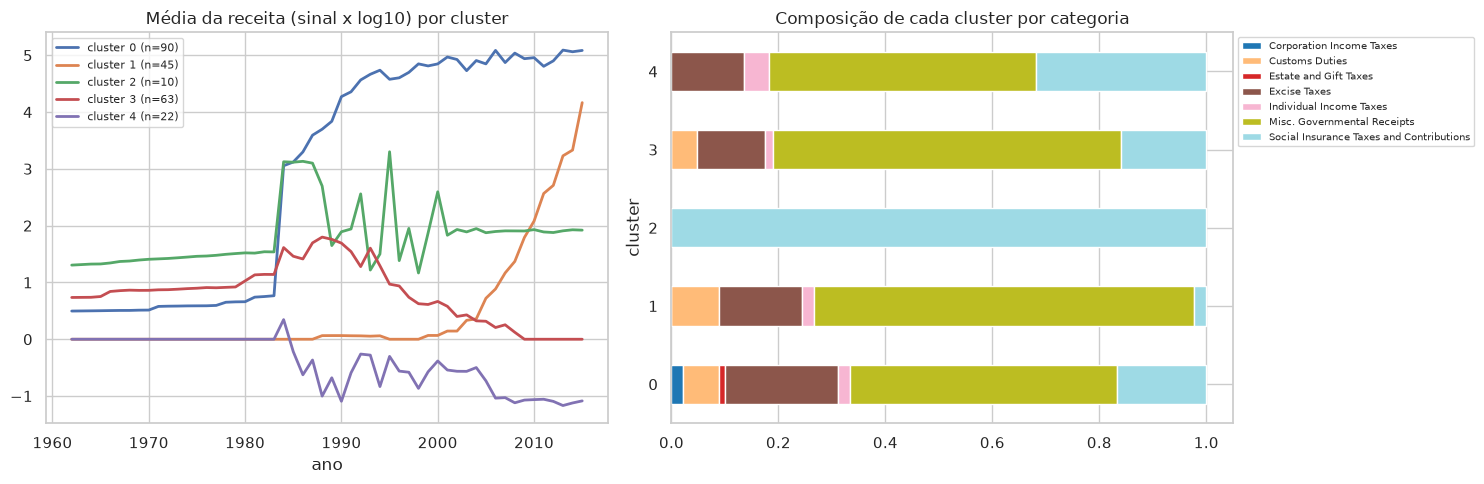

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for c in range(K):
    serie = slog(V[base["cluster"] == c])
    axes[0].plot(anos_arr, serie.mean(axis=0), label=f"cluster {c} (n={len(serie)})", lw=2)
axes[0].set_title("Média da receita (sinal x log10) por cluster")
axes[0].set_xlabel("ano"); axes[0].legend(fontsize=8)

(base.groupby("cluster")["categoria"].value_counts(normalize=True).unstack(fill_value=0)
     .plot.barh(stacked=True, ax=axes[1], cmap="tab20"))
axes[1].set_title("Composição de cada cluster por categoria")
axes[1].legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [20]:
# 5 maiores contas (por total arrecadado) de cada cluster, para dar sentido aos grupos
for c in range(K):
    print(f"--- Cluster {c} ---")
    sub = base[base["cluster"] == c].nlargest(5, "total_hist")
    print(sub[["categoria", "conta", "total_hist"]].assign(total_hist=lambda d: (d.total_hist / 1e6).round(1))
          .rename(columns={"total_hist": "total (US$ bi)"}).to_string(index=False))
    print()

--- Cluster 0 ---
                               categoria                                                    conta  total (US$ bi)
                 Individual Income Taxes                                  Individual Income Taxes         28226.6
                Corporation Income Taxes              Corporation Income and Excess Profits Taxes          6577.4
Social Insurance Taxes and Contributions FHI Trust Fund, Transfers from General Fund (FICA Taxes)          3840.7
             Misc. Governmental Receipts              Deposit of Earnings, Federal Reserve System          1100.2
                            Excise Taxes    Transportation Trust Fund, Deposits (Highway Account)           911.1

--- Cluster 1 ---
                  categoria                                                                                         conta  total (US$ bi)
             Customs Duties 30 Percent of Customs Duties, Funds for Strengthening Markets, Income and Supply (section 32)            70.5
   

### 6.5 Interpretação do K-Means (k = 5)

Escolhemos **k = 5**: a silhueta sobe de forma clara até k = 5 (0,40) e os grupos têm uma explicação fácil de contar. Valores maiores (6 e 7) melhoram pouco a silhueta, mas só dividem grupos pequenos.

| Cluster | Contas | Perfil | Exemplos |
|---|---|---|---|
| **0 - Receitas grandes e permanentes** | 90 | Ativas há ~30 anos e ainda existem em 2015; concentram **73%** de tudo que foi arrecadado | Imposto de renda de pessoas físicas, imposto de renda de empresas, lucros do Federal Reserve |
| **1 - Receitas novas** | 45 | Começaram em média em 2009, poucos anos de histórico e crescimento enorme (muitas nasceram com a reforma da saúde) | Taxas sobre seguradoras de saúde e indústria farmacêutica, fundo do tabaco |
| **2 - Previdência (fora do orçamento)** | 10 | Todas `off_budget`; são só **10 contas, mas 25%** da arrecadação, com valores negativos ocasionais | Transferências FICA/SECA para o Seguro Social (FOASI, FDI) |
| **3 - Receitas encerradas** | 63 | Pararam em média em 1994, poucos anos ativos e valor atual zero | Imposto sobre lucros extraordinários do petróleo (*windfall profit tax*), antigas tarifas |
| **4 - Contas instáveis / de ajuste** | 22 | Valores muito oscilantes (`cv` alto) e 63% dos anos negativos (reembolsos); total líquido ~0 | Fundos de confisco, taxas sobre pesca, depósitos de estados |

Ou seja, o algoritmo separou as contas principalmente pelo **ciclo de vida** (antigas, novas, encerradas) e pela **natureza do fluxo** (previdência, ajustes), sem ter recebido a categoria oficial. Isso mostra que o nome da categoria não conta toda a história, já que "Misc. Governmental Receipts", por exemplo, se espalha por quase todos os clusters.

## 7. Outros algoritmos de clustering

Para comparar, aplicamos mais três algoritmos do scikit-learn sobre as mesmas características padronizadas.

### 7.1 Affinity Propagation

Não precisa definir o número de clusters: ele escolhe sozinho "exemplares". O parâmetro `preference` controla quantos grupos saem (quanto menor, menos grupos).

In [21]:
S = -((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2)   # similaridade = -distância^2
resultados = []
for q in [0, 10, 25, 50, 75, 100]:
    pref = np.percentile(S, q) if q else S.min()
    ap = AffinityPropagation(preference=pref, damping=0.9, max_iter=1000, random_state=RANDOM_STATE).fit(X)
    n = len(ap.cluster_centers_indices_)
    resultados.append({"percentil_preference": q, "preference": round(pref, 1), "n_clusters": n,
                       "silhueta": silhouette_score(X, ap.labels_) if 1 < n < len(X) else np.nan})
pd.DataFrame(resultados).round(3)

,percentil_preference,preference,n_clusters,silhueta
0,0,-113.5,5,0.399
1,10,-39.1,14,0.375
2,25,-25.7,1,NaN
3,50,-14.0,2,0.288
4,75,-7.0,2,0.288
5,100,0.0,230,NaN


In [22]:
ap = AffinityPropagation(preference=np.percentile(S, 0), damping=0.9, max_iter=1000, random_state=RANDOM_STATE).fit(X)
print("Clusters encontrados:", len(ap.cluster_centers_indices_), "| silhueta:", round(silhouette_score(X, ap.labels_), 3))
print(pd.Series(ap.labels_).value_counts().sort_index().to_string())

Clusters encontrados: 5 | silhueta: 0.399
0    10
1    90
2    23
3    63
4    44


### 7.2 Agrupamento hierárquico (Ward)

O dendrograma mostra como os grupos vão sendo unidos; aqui usamos o mesmo `k` do K-Means para comparar.

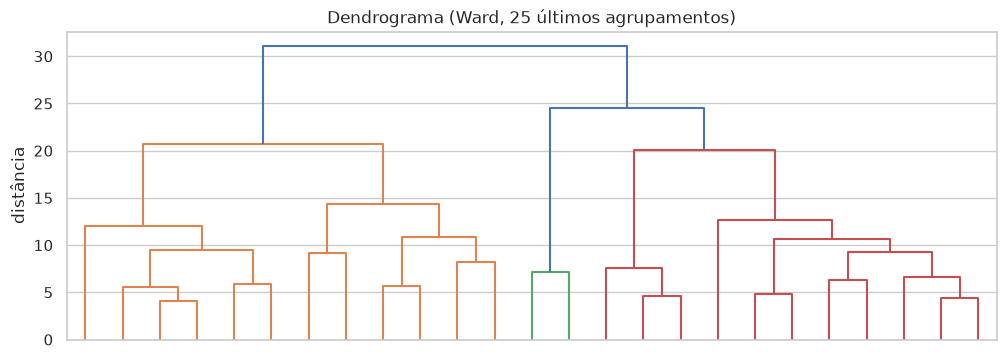

silhueta: 0.377
0     25
1    100
2     37
3     60
4      8


In [23]:
from scipy.cluster.hierarchy import dendrogram, linkage

Z = linkage(X, method="ward")
plt.figure(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=25, show_leaf_counts=True, no_labels=True)
plt.title("Dendrograma (Ward, 25 últimos agrupamentos)")
plt.ylabel("distância")
plt.show()

agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
print("silhueta:", round(silhouette_score(X, agg.labels_), 3))
print(pd.Series(agg.labels_).value_counts().sort_index().to_string())

### 7.3 DBSCAN

Agrupa por **densidade** e marca como ruído (`-1`) os pontos isolados. Procuramos um `eps` razoável com uma pequena busca.

In [24]:
linhas = []
for eps in [0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    n = len(set(lab) - {-1})
    m = lab != -1
    linhas.append({"eps": eps, "n_clusters": n, "ruído": int((~m).sum()),
                   "silhueta (sem ruído)": silhouette_score(X[m], lab[m]) if n > 1 else np.nan})
pd.DataFrame(linhas).round(3)

,eps,n_clusters,ruído,silhueta (sem ruído)
0,0.8,7,83,0.539
1,1.0,7,63,0.510
2,1.2,6,49,0.262
3,1.5,2,27,0.462
4,1.8,2,22,0.447
5,2.0,2,21,0.445
6,2.5,2,16,0.422


In [25]:
dbscan = DBSCAN(eps=1.0, min_samples=5).fit(X)
print("Clusters:", len(set(dbscan.labels_) - {-1}), "| ruído:", int((dbscan.labels_ == -1).sum()))
print(pd.Series(dbscan.labels_).value_counts().sort_index().to_string())

Clusters: 7 | ruído: 63
-1    63
 0    23
 1    82
 2     7
 3     9
 4    10
 5    32
 6     4


### 7.4 Comparação dos modelos

In [26]:
modelos = {"K-Means": kmeans.labels_, "Affinity Propagation": ap.labels_,
           "Hierárquico (Ward)": agg.labels_, "DBSCAN": dbscan.labels_}

linhas = []
for nome, lab in modelos.items():
    m = lab != -1
    n = len(set(lab[m]))
    linhas.append({
        "modelo": nome,
        "n_clusters": n,
        "ruído": int((~m).sum()),
        "silhueta": silhouette_score(X[m], lab[m]),
        "davies_bouldin": davies_bouldin_score(X[m], lab[m]),
        "calinski_harabasz": calinski_harabasz_score(X[m], lab[m]),
        "ARI vs K-Means": adjusted_rand_score(kmeans.labels_, lab),
    })
comparacao = pd.DataFrame(linhas).set_index("modelo").round(3)
comparacao

,n_clusters,ruído,silhueta,davies_bouldin,calinski_harabasz,ARI vs K-Means
modelo,,,,,,
K-Means,5,0,0.401,1.063,89.026,1.000
Affinity Propagation,5,0,0.399,1.068,88.600,0.982
Hierárquico (Ward),5,0,0.377,1.100,77.808,0.782
DBSCAN,7,63,0.510,0.608,118.034,0.473


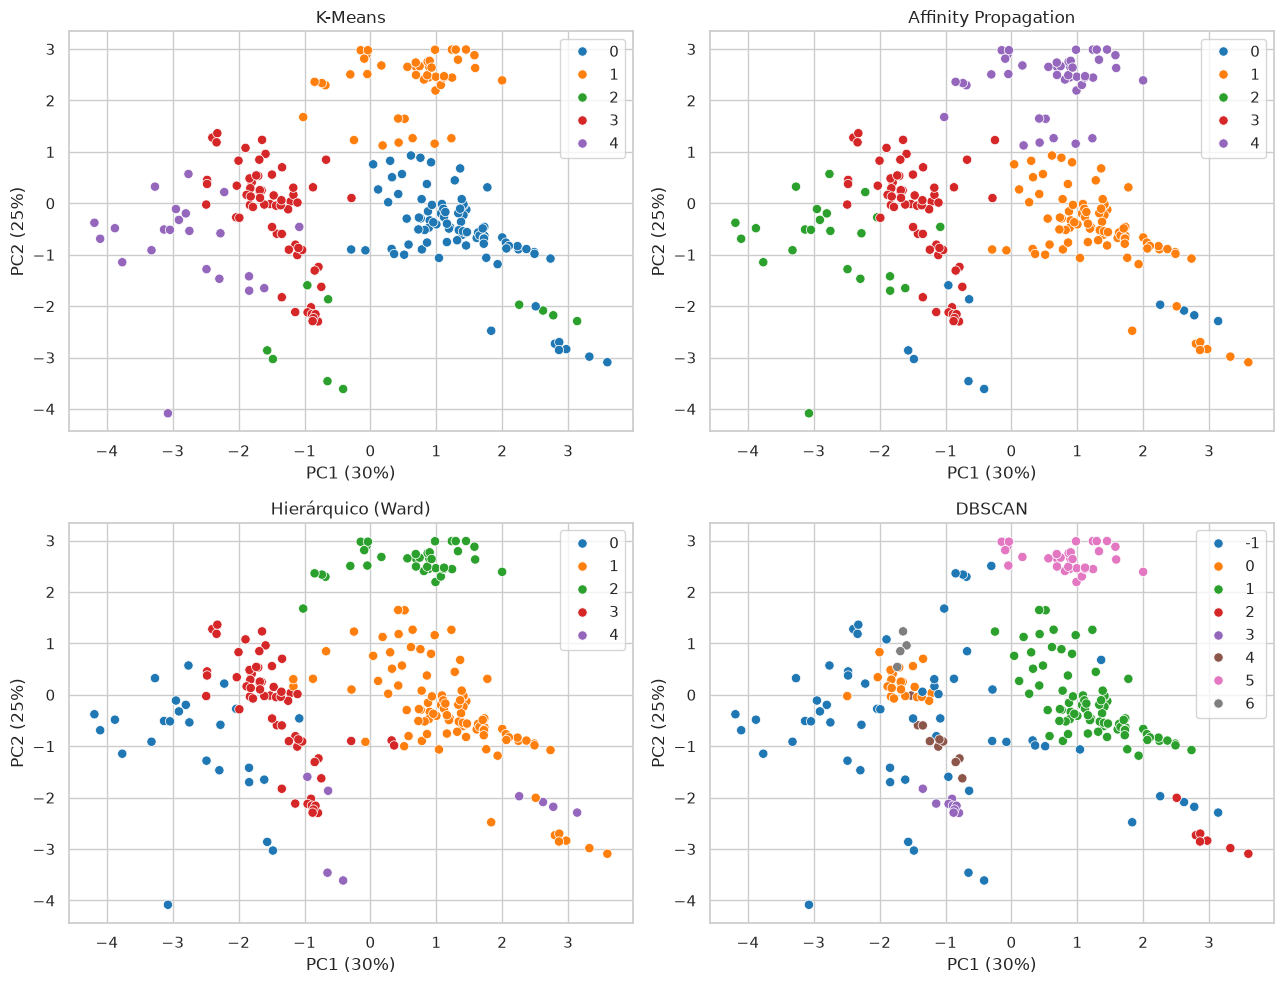

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (nome, lab) in zip(axes.ravel(), modelos.items()):
    plot_pca(lab, f"{nome}", ax)
plt.tight_layout()
plt.show()

## 8. Conclusões

- **K-Means (k = 5)** foi o modelo escolhido: silhueta de 0,40, Davies-Bouldin de 1,06 e grupos fáceis de interpretar (ciclo de vida das receitas + previdência + contas de ajuste).
- **Affinity Propagation** achou sozinho também 5 clusters (silhueta 0,40) e ficou quase igual ao K-Means (**ARI = 0,98**), o que dá confiança de que a estrutura é real e não um efeito do K escolhido.
- **Hierárquico (Ward)** concordou menos (ARI = 0,78) e teve silhueta um pouco menor.
- **DBSCAN** teve a melhor silhueta (0,51), mas só porque joga 63 contas (27%) como ruído e ignora os pontos mais difíceis; por isso o resultado não é diretamente comparável. Ele serve para mostrar que existe um núcleo denso de contas "normais" e vários outliers (contas enormes como imposto de renda).
- **Limitações:** o dataset é pequeno (230 contas), as características foram escolhidas por nós (outra escolha poderia mudar os grupos), as contas gigantes são outliers naturais e valores de 2016-2020 são projeções, por isso ficaram fora.
- **Próximos passos:** testar outras características (por exemplo a série temporal normalizada, com *time series k-means*), usar também a tabela de despesas (*outlays*) do mesmo orçamento e comparar com outros anos de orçamento.

### Referências
- scikit-learn, *Clustering*: https://scikit-learn.org/stable/modules/clustering.html
- U.S. GPO, *Public Budget Database FY2016*: https://www.govinfo.gov/app/details/BUDGET-2016-DB/BUDGET-2016-DB-3